# 02 — Model Training

**Project:** Driver Drowsiness Detection System
**Goal of this notebook:** train the models that classify an image as `Closed`, `Open`, `no_yawn` or `yawn`.

- **Part A (Step 2): baseline custom CNN** — a small network built from scratch, to set a baseline.
- **Part B (Step 3): MobileNetV2 transfer learning** — added later in this same notebook, reusing the same data pipeline and augmentation.

| | |
|---|---|
| **Input** | `model/artifacts/data_config.json` and `data/processed/{train,val}/` (both from notebook 01) |
| **Output 1** | `model/saved_models/custom_cnn.keras` — the best trained model |
| **Output 2** | `model/artifacts/history_custom_cnn.json` — loss/accuracy for every epoch |
| **Output 3** | `model/results/02_custom_cnn_curves.png` — training curves |

> The **test** split is **not** used here. It is kept for the final evaluation in notebook 03.

**Steps:** 1. Setup → 2. Configuration → 3. Data pipeline → 4. Data augmentation → 5. Custom CNN → 6. Sanity check → 7. Callbacks → 8. Train → 9. Training curves → 10. Verify saved model → 11. Summary

## 1. Setup

Imports, the same project-root setup as notebook 01, and a **global random seed** so that weight initialization, shuffling and augmentation are the same on every run (reproducible results).

In [3]:
import json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

# The notebook runs from the model/ folder, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "model" else Path.cwd()
print("Project root:", PROJECT_ROOT)
print("TensorFlow  :", tf.__version__, "| Keras:", keras.__version__)
print("GPU         :", tf.config.list_physical_devices("GPU") or "none (training on CPU)")

Project root: /content
TensorFlow  : 2.20.0 | Keras: 3.13.2
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configuration

**Data settings are not typed here** — they are read from `data_config.json`, written by notebook 01. This guarantees the classes, image size and seed are identical across all notebooks and the backend.

The training hyper-parameters are defined here:

| Setting | Value | Why |
|---|---|---|
| `BATCH_SIZE` | `32` | Standard size: stable gradients, fits easily in CPU memory. |
| `EPOCHS` | `80` | Upper limit only — early stopping (Section 7) ends training when validation loss stops improving. (The first run with 40 was still improving at the cap.) |
| `LEARNING_RATE` | `1e-3` | The default for the Adam optimizer; reduced automatically when progress stalls. |
| `PATIENCE` | `15` | Stop if validation loss has not improved for 15 epochs in a row. (Validation loss is noisy on 371 images; with 10, run 2 stopped at epoch 19 while the model was still learning.) |
| `LR_PATIENCE` | `5` | Halve the learning rate after 5 epochs without improvement. (With 3, the first run cut the rate 7× and learning slowed to a crawl.) |

In [4]:
MODEL_DIR     = PROJECT_ROOT / "model"
ARTIFACTS_DIR = MODEL_DIR / "artifacts"
SAVED_DIR     = MODEL_DIR / "saved_models"
RESULTS_DIR   = MODEL_DIR / "results"
for folder in (SAVED_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

data_config = json.loads((ARTIFACTS_DIR / "data_config.json").read_text())
CLASSES  = data_config["classes"]
IMG_SIZE = data_config["img_size"]
SEED     = data_config["seed"]
TRAIN_DIR = PROJECT_ROOT / data_config["paths"]["train"]
VAL_DIR   = PROJECT_ROOT / data_config["paths"]["val"]

BATCH_SIZE    = 32
EPOCHS        = 80
LEARNING_RATE = 1e-3
PATIENCE      = 15
LR_PATIENCE   = 5

# Chart colors (colorblind-safe pair): blue = train, orange = validation
COLORS = {"train": "#2a78d6", "val": "#eb6834"}

keras.utils.set_random_seed(SEED)
print("Classes   :", CLASSES)
print("Image size:", IMG_SIZE, "| Seed:", SEED)

Classes   : ['Closed', 'Open', 'no_yawn', 'yawn']
Image size: 128 | Seed: 42


## 3. Data pipeline

`keras.utils.image_dataset_from_directory` reads the `data/processed/<split>/<class>/` folders and produces batches of `(images, labels)`:

- **Labels** come from the folder names. We pass `class_names=CLASSES` explicitly, so label `0` is always `Closed`, `1` is `Open`, `2` is `no_yawn`, `3` is `yawn`.
- **Resizing** to `128 × 128` (bilinear) happens while loading. Pixels stay in the `0–255` range — normalization is done inside the model.
- **Shuffling** only for training data, so every epoch sees the images in a different order.
- **`.cache()`** keeps decoded images in memory after the first epoch (no repeated JPEG decoding), and **`.prefetch()`** prepares the next batch while the current one is training.

In [5]:
def load_split(folder: Path, shuffle: bool) -> tf.data.Dataset:
    # Batched (image, label) dataset from a class-per-folder directory, cached and prefetched.
    ds = keras.utils.image_dataset_from_directory(
        folder, class_names=CLASSES, image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED)  # defaults: int labels, bilinear resize
    return ds.cache().prefetch(tf.data.AUTOTUNE)


train_ds = load_split(TRAIN_DIR, shuffle=True)
val_ds   = load_split(VAL_DIR, shuffle=False)

images, labels = next(iter(train_ds))
print("\nOne batch  -> images:", images.shape, images.dtype, "| labels:", labels.shape, labels.dtype)
print(f"Pixel range: {float(tf.reduce_min(images)):.0f} – {float(tf.reduce_max(images)):.0f}  (raw; the model normalizes)")
print("Labels in this batch:", [CLASSES[i] for i in labels[:8].numpy()], "...")

Found 2096 files belonging to 4 classes.
Found 371 files belonging to 4 classes.

One batch  -> images: (32, 128, 128, 3) <dtype: 'float32'> | labels: (32,) <dtype: 'int32'>
Pixel range: 0 – 255  (raw; the model normalizes)
Labels in this batch: ['Closed', 'no_yawn', 'no_yawn', 'yawn', 'Closed', 'Open', 'no_yawn', 'Closed'] ...


## 4. Data augmentation

With only ~2,100 training images, a network can simply **memorize** them (overfitting). Augmentation creates a slightly different version of every image each time it is seen, so the model has to learn the real features (eyelid shape, open mouth) instead of exact pixels.

| Layer | Setting | What it simulates |
|---|---|---|
| `RandomFlip("horizontal")` | mirror left ↔ right | left eye vs right eye; driver facing slightly left or right |
| `RandomRotation(0.05)` | up to ±18° | head tilt |
| `RandomZoom(0.1)` | up to ±10 % | driver closer to / further from the camera |
| `RandomBrightness(0.2)` | up to ±20 % | day / night / shadow lighting changes |

**Key detail:** these are Keras layers placed **inside the model**. Keras only activates them during training (`model.fit`). During evaluation and prediction they do nothing — so validation, test and the real-time backend always see the original image.

In [6]:
def build_augmentation() -> keras.Sequential:
    # Random image transformations, active only while training.
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.05, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
        layers.RandomBrightness(0.2, value_range=(0, 255), seed=SEED),
    ], name="augmentation")

Below: one eye image and one yawn-frame image from the batch above, each shown as the original plus five random augmented versions.

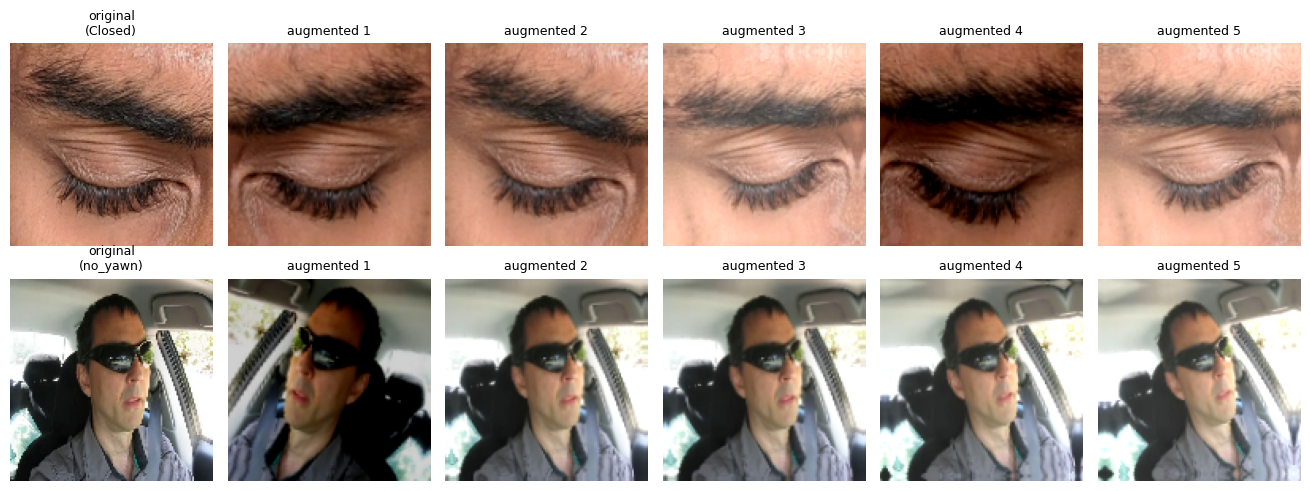

In [7]:
def show_augmentations(augmentation: keras.Sequential, images, labels, n: int = 5):
    # Original image + n augmented versions, for the first eye image and the first yawn-frame image in a batch.
    labels = labels.numpy()
    picks = [int(np.argmax(labels <= 1)), int(np.argmax(labels >= 2))]  # first eye image (0/1), first yawn frame (2/3)
    fig, axes = plt.subplots(len(picks), n + 1, figsize=(2.2 * (n + 1), 2.5 * len(picks)))
    for row, i in enumerate(picks):
        img = images[i]
        axes[row, 0].imshow(img.numpy().astype("uint8"))
        axes[row, 0].set_title(f"original\n({CLASSES[labels[i]]})", fontsize=9)
        for col in range(1, n + 1):
            aug = augmentation(img[None], training=True)[0]
            axes[row, col].imshow(np.clip(aug.numpy(), 0, 255).astype("uint8"))
            axes[row, col].set_title(f"augmented {col}", fontsize=9)
        for ax in axes[row]:
            ax.axis("off")
    fig.tight_layout()
    plt.show()


show_augmentations(build_augmentation(), images, labels)

## 5. Part A — Baseline custom CNN

A deliberately **small and simple** convolutional network, to establish a working baseline before adding complexity.

**Building block** — each *conv block* does:
1. `Conv2D` (3×3 filters) — learns local patterns: edges → textures → eyelids / mouth shapes in deeper blocks.
2. `BatchNormalization(momentum=0.9)` — keeps activations in a stable range → faster, more stable training. At evaluation time it uses *running averages* of the batch statistics; `momentum=0.9` makes those averages follow the changing weights about 10× faster than the default `0.99`. With the default, validation accuracy lagged far behind training (stuck at 25 % for the first epochs, then ~70 %), because it was scored with out-of-date statistics.
3. `ReLU` — non-linearity, so the network can learn complex shapes.
4. `MaxPooling2D` (2×2) — halves width and height: keeps the strongest responses and reduces computation.

In [8]:
def conv_block(x, filters: int):
    # Conv 3x3 -> BatchNorm -> ReLU -> MaxPool (halves the spatial size).
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)  # no bias: BatchNorm adds its own shift
    x = layers.BatchNormalization(momentum=0.9)(x)  # faster-updating running stats (default 0.99 lagged)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

**Full network:**

```
Input 128×128×3 (raw 0–255 pixels)
 → Augmentation (training only)
 → Rescaling 1/255            → pixels in 0–1
 → conv block  32 filters     → 64×64×32
 → conv block  64 filters     → 32×32×64
 → conv block 128 filters     → 16×16×128
 → conv block 256 filters     →  8×8×256
 → GlobalAveragePooling       → 256 numbers (one per filter)
 → Dropout 0.4                → randomly drops 40 % during training (anti-overfitting)
 → Dense 4 + softmax          → probability for each class (sums to 1)
```

**Design choices:**
- **Filters double as the image shrinks** — a standard CNN pattern: fewer, simpler features at high resolution; more, richer features at low resolution.
- **GlobalAveragePooling instead of Flatten** — Flatten + Dense would add millions of weights. GAP keeps this model at **≈ 0.4 M parameters** → faster on CPU and less prone to overfitting.
- **Normalization inside the model** (`Rescaling`) — the deployed model accepts raw pixels, so the backend cannot apply the wrong preprocessing.
- **Loss = sparse categorical cross-entropy** — the standard loss for single-label multi-class classification with integer labels.

In [9]:
def build_custom_cnn(num_classes: int) -> keras.Model:
    # Baseline CNN: augmentation -> rescaling -> 4 conv blocks -> GAP -> dropout -> softmax.
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255, name="rescale_0_1")(x)
    for filters in (32, 64, 128, 256):
        x = conv_block(x, filters)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="class_probs")(x)

    model = keras.Model(inputs, outputs, name="custom_cnn")
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


custom_cnn = build_custom_cnn(len(CLASSES))
custom_cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probs (Dense)             │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 390,884 (1.49 MB)

 Trainable params: 389,924 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

## 6. Sanity check (before training)

A quick check that the pipeline and model fit together, **without training**:

- Output shape must be `(batch, 4)` and each row must sum to `1` (softmax probabilities).
- An **untrained** 4-class model should be guessing, i.e. roughly equal probabilities and a loss close to **ln(4) ≈ 1.386**. A very different value would point to a bug (wrong labels, wrong normalization).

In [10]:
val_images, val_labels = next(iter(val_ds))
probs = custom_cnn.predict(val_images, verbose=0)
loss = keras.losses.sparse_categorical_crossentropy(val_labels, probs).numpy().mean()

print("Output shape        :", probs.shape)
print("Row sums (first 5)  :", np.round(probs.sum(axis=1)[:5], 4))
print("Mean probability    :", {c: round(float(p), 3) for c, p in zip(CLASSES, probs.mean(axis=0))})
print(f"Untrained loss      : {loss:.3f}   (random-guess baseline ln(4) = {np.log(4):.3f})")

Output shape        : (32, 4)
Row sums (first 5)  : [1. 1. 1. 1. 1.]
Mean probability    : {'Closed': 0.254, 'Open': 0.254, 'no_yawn': 0.243, 'yawn': 0.249}
Untrained loss      : 1.370   (random-guess baseline ln(4) = 1.386)


## 7. Training callbacks

Callbacks run automatically at the end of every epoch:

| Callback | What it does | Why |
|---|---|---|
| `ModelCheckpoint` | saves the model to `saved_models/custom_cnn.keras` whenever validation loss improves | we keep the **best** epoch, not the last one |
| `EarlyStopping` | stops when validation loss has not improved for `PATIENCE` epochs, and restores the best weights | avoids wasting time and over-training |
| `ReduceLROnPlateau` | halves the learning rate after `LR_PATIENCE` epochs without improvement | smaller steps help the model settle into a better minimum |

We monitor **validation loss** rather than validation accuracy: with 371 validation images, accuracy moves in coarse steps, while loss changes smoothly and also reflects *how confident* the predictions are.

In [11]:
def make_callbacks(model_name: str) -> list:
    # Checkpoint the best model, stop early, and lower the learning rate on plateaus.
    return [
        keras.callbacks.ModelCheckpoint(SAVED_DIR / f"{model_name}.keras", monitor="val_loss",
                                        save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE,
                                          min_lr=1e-6, verbose=1),
    ]

## 8. Train the custom CNN

`model.fit` runs the training loop: for every batch it predicts, measures the loss, and updates the weights with Adam. After every epoch it evaluates on the validation set and runs the callbacks.

The per-epoch history (loss and accuracy for train and validation) is saved to JSON, so notebook 03 and the final report can use it without retraining.

In [12]:
def train(model: keras.Model, model_name: str) -> dict:
    # Fit the model, save its history to artifacts/, and return the history dict.
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                        callbacks=make_callbacks(model_name), verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    hist["train_seconds"] = round(time.time() - start, 1)
    hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1
    (ARTIFACTS_DIR / f"history_{model_name}.json").write_text(json.dumps(hist, indent=2))
    print(f"\nTraining time: {hist['train_seconds'] / 60:.1f} min | best epoch: {hist['best_epoch']}")
    return hist


custom_hist = train(custom_cnn, "custom_cnn")

Epoch 1/80

Epoch 1: val_loss improved from None to 0.63632, saving model to /content/model/saved_models/custom_cnn.keras

Epoch 1: finished saving model to /content/model/saved_models/custom_cnn.keras
66/66 - 11s - 166ms/step - accuracy: 0.5568 - loss: 0.8628 - val_accuracy: 0.6712 - val_loss: 0.6363 - learning_rate: 0.0010
Epoch 2/80

Epoch 2: val_loss improved from 0.63632 to 0.60674, saving model to /content/model/saved_models/custom_cnn.keras

Epoch 2: finished saving model to /content/model/saved_models/custom_cnn.keras
66/66 - 3s - 44ms/step - accuracy: 0.6155 - loss: 0.7231 - val_accuracy: 0.7332 - val_loss: 0.6067 - learning_rate: 0.0010
Epoch 3/80

Epoch 3: val_loss improved from 0.60674 to 0.56402, saving model to /content/model/saved_models/custom_cnn.keras

Epoch 3: finished saving model to /content/model/saved_models/custom_cnn.keras
66/66 - 3s - 44ms/step - accuracy: 0.6560 - loss: 0.6642 - val_accuracy: 0.6577 - val_loss: 0.5640 - learning_rate: 0.0010
Epoch 4/80

Epoch

## 9. Training curves

How to read them:

- **Both curves improving together** → the model is learning general patterns.
- **Train accuracy keeps rising while validation accuracy flattens or drops** (validation loss rising) → **overfitting**.
- **Both curves stuck low** → **underfitting** (model too small or learning rate wrong).

The dashed line marks the **best epoch** (lowest validation loss) — that is the model that was saved.

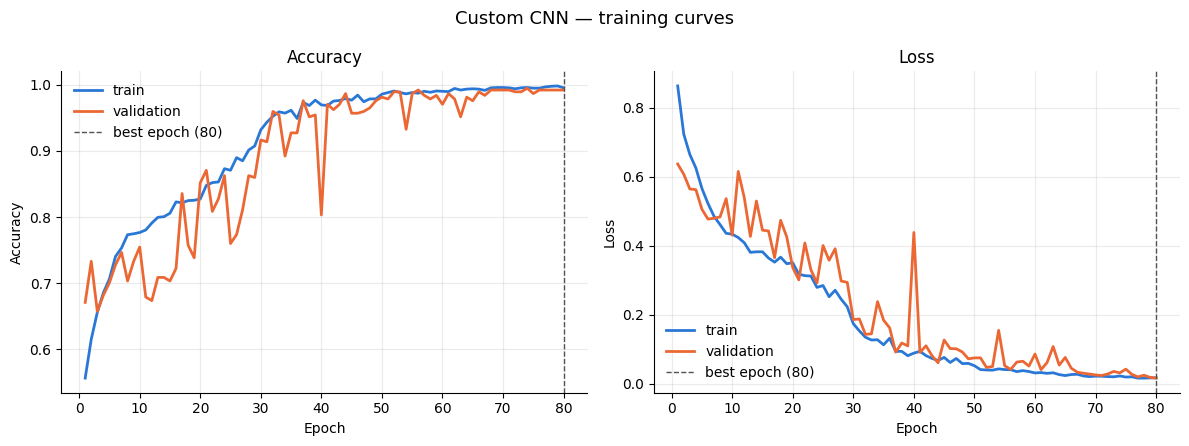

Best epoch 80: train acc 0.9952 | val acc 0.9919 | train loss 0.0164 | val loss 0.0158
Train–val accuracy gap: +0.0033  (large positive = overfitting)


In [13]:
def plot_history(hist: dict, title: str, save_path: Path):
    # Accuracy and loss curves (train vs validation) with the best epoch marked.
    epochs = np.arange(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, metric, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(epochs, hist[metric], color=COLORS["train"], lw=2, label="train")
        ax.plot(epochs, hist[f"val_{metric}"], color=COLORS["val"], lw=2, label="validation")
        ax.axvline(hist["best_epoch"], color="#52514e", ls="--", lw=1, label=f"best epoch ({hist['best_epoch']})")
        ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_title(label)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(alpha=0.25)
        ax.legend(frameon=False)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


plot_history(custom_hist, "Custom CNN — training curves", RESULTS_DIR / "02_custom_cnn_curves.png")

b = custom_hist["best_epoch"] - 1
print(f"Best epoch {b + 1}: train acc {custom_hist['accuracy'][b]:.4f} | val acc {custom_hist['val_accuracy'][b]:.4f} "
      f"| train loss {custom_hist['loss'][b]:.4f} | val loss {custom_hist['val_loss'][b]:.4f}")
print(f"Train–val accuracy gap: {custom_hist['accuracy'][b] - custom_hist['val_accuracy'][b]:+.4f}  (large positive = overfitting)")

## 10. Verify the saved model

The checkpoint file on disk is what later notebooks and the backend will use, so we **reload it from disk** and evaluate it on the validation set. The numbers must match the best epoch above — this proves the saved file is correct and self-contained (augmentation and rescaling layers included).

In [ ]:
reloaded = keras.models.load_model(SAVED_DIR / "custom_cnn.keras")
val_loss, val_acc = reloaded.evaluate(val_ds, verbose=0)
print(f"Reloaded custom_cnn.keras -> val loss {val_loss:.4f} | val accuracy {val_acc:.4f}")
print(f"File size: {(SAVED_DIR / 'custom_cnn.keras').stat().st_size / 1e6:.2f} MB | parameters: {reloaded.count_params():,}")

Reloaded custom_cnn.keras -> val loss 0.0158 | val accuracy 0.9919
File size: 4.78 MB | parameters: 390,884


## 11. Summary — Part A

- A **≈ 0.4 M-parameter** custom CNN was trained with augmentation, early stopping and learning-rate reduction.
- The best model (lowest validation loss) is saved at `model/saved_models/custom_cnn.keras`, its history at `model/artifacts/history_custom_cnn.json`, and its curves at `model/results/02_custom_cnn_curves.png`.
- Final **test-set** metrics (accuracy, precision, recall, F1, confusion matrix) are computed in **notebook 03**, not here.

**Next → Part B (Step 3):** MobileNetV2 transfer learning, added below in this notebook with the same pipeline and augmentation.